# Tutorial: Encoder-decoder Transformer for translation

Transformers were invented for machine translation. An **encoder** reads a sentence in one language and a **decoder** writes it in another, one token at a time. Training a real translator takes hours on a GPU, so in this tutorial the model learns a small 'language' instead, one it can learn in a few minutes on a CPU: dates written in English, translated into the ISO 8601 format that computers use.

| Input (English) | Output (ISO 8601) |
|---|---|
| march 5 2021 | 2021-03-05 |
| 5 march 2021 | 2021-03-05 |
| mar 5 2021 | 2021-03-05 |
| the 5th of march 2021 | 2021-03-05 |

To do this, the model has to find the year, the month and the day wherever they appear in the input and put them in a new order, which is the same skill a translator needs.

# Background - Encoder, decoder and cross-attention

* The **encoder** is a stack of the self-attention blocks from `tf.keras_transformer_songs.ipynb`. It reads the whole input at once.
* The **decoder** writes the output one character at a time. Each decoder block has three parts:
  1. **masked self-attention** over the characters written so far, using the causal mask from `attention_numpy.ipynb` so that it can't look ahead;
  2. **cross-attention**, where the queries come from the decoder and the keys and values come from the encoder's output: "which input words matter for the character I am writing now?";
  3. a **feed-forward network**.
* During **training**, the decoder is given the correct output shifted one step to the right. It sees `[start] 2 0 2 1 - 0 3 - 0` and must predict `2 0 2 1 - 0 3 - 0 5 [end]`, all positions at once. This is called *teacher forcing*.
* To **translate** a new date, we start with `[start]` alone and feed back the most likely next character, again and again. This is called *greedy decoding*.

# Step 0 - Setup the learning environment

We import the Keras modules and some plotting tools, and set the learning parameters.

In [1]:
'''
tf.keras_transformer_dates.py

Trains a small encoder-decoder Transformer to translate dates written in English
('the 5th of march 2021') into ISO format ('2021-03-05').
Uses a separate validation/tuning set with early stopping, then translates the
test set with greedy decoding. Takes a few minutes on a CPU.
'''

import os
import warnings
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'   # hide TensorFlow's information messages
warnings.filterwarnings('ignore')

import datetime
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt

tf.get_logger().setLevel('ERROR')          # hide TensorFlow's deprecation warnings
np.random.seed(2)          # for consistency
tf.random.set_seed(2)

num_examples = 20000       # date pairs to generate
batch_size = 64
epochs = 20                # the most epochs we allow; early stopping usually ends sooner

print(tf.__version__)
print('Environment is ready!')


2.15.0
Environment is ready!


# Step 1 - Create and prepare the data

We generate random dates between 1950 and 2049 and write each one in one of the four English formats. The input is split into **words**, and the output is split into **characters**. Each word and character gets an integer index:

* `[pad]` fills short inputs up to the longest input length (5 words), and the model is told to ignore it.
* `[unk]` stands for any word the model has never seen.
* `[start]` and `[end]` mark the beginning and end of the output.

The data is then split into three sets: training (80%), validation or tuning (10%) and testing (10%).

In [2]:
months = ['january', 'february', 'march', 'april', 'may', 'june', 'july',
          'august', 'september', 'october', 'november', 'december']
month_abbrev = [m[:3] for m in months]


def ordinal(day):
    """1 -> '1st', 2 -> '2nd', 3 -> '3rd', 4 -> '4th', 11 -> '11th', 22 -> '22nd', ..."""
    if 10 <= day % 100 <= 20:
        suffix = 'th'
    else:
        suffix = {1: 'st', 2: 'nd', 3: 'rd'}.get(day % 10, 'th')
    return str(day) + suffix


# The four ways of writing a date in English
formats = [
    lambda d: '{0} {1} {2}'.format(months[d.month - 1], d.day, d.year),                 # march 5 2021
    lambda d: '{0} {1} {2}'.format(d.day, months[d.month - 1], d.year),                 # 5 march 2021
    lambda d: '{0} {1} {2}'.format(month_abbrev[d.month - 1], d.day, d.year),           # mar 5 2021
    lambda d: 'the {0} of {1} {2}'.format(ordinal(d.day), months[d.month - 1], d.year), # the 5th of march 2021
]

first_day, last_day = datetime.date(1950, 1, 1), datetime.date(2049, 12, 31)
num_days = (last_day - first_day).days + 1


def random_pair():
    """A random date, written in a random English format, and the same date in ISO format."""
    date = first_day + datetime.timedelta(days=int(np.random.randint(num_days)))
    english = formats[np.random.randint(len(formats))](date)
    return english, date.isoformat()


pairs = [random_pair() for _ in range(num_examples)]
for english, iso in pairs[:5]:
    print('{0:28s} -> {1}'.format(english, iso))

the 11th of december 2014    -> 2014-12-11
march 4 1968                 -> 1968-03-04
dec 5 2034                   -> 2034-12-05
september 22 2042            -> 2042-09-22
the 25th of november 2040    -> 2040-11-25


In [3]:
PAD, UNK, START, END = '[pad]', '[unk]', '[start]', '[end]'

# Input vocabulary: every word that appears in the English dates
src_vocab = [PAD, UNK] + sorted({word for english, _ in pairs for word in english.split()})
# Output vocabulary: the 11 characters of an ISO date
tgt_vocab = [PAD, START, END] + list('0123456789-')
src_index = {word: i for i, word in enumerate(src_vocab)}
tgt_index = {char: i for i, char in enumerate(tgt_vocab)}

src_len = max(len(english.split()) for english, _ in pairs)   # longest input: 5 words
date_len = 10                                                  # an ISO date always has 10 characters
tgt_len = date_len + 1                                         # plus [start] or [end]


def encode_english(english):
    """Words -> indices, padded with [pad] (index 0) up to src_len. Unknown words become [unk]."""
    ids = [src_index.get(word, src_index[UNK]) for word in english.split()]
    return ids + [src_index[PAD]] * (src_len - len(ids))


source = np.array([encode_english(english) for english, _ in pairs])            # (num_examples, 5)
target = np.array([[tgt_index[c] for c in iso] for _, iso in pairs])            # (num_examples, 10)
start_column = np.full((num_examples, 1), tgt_index[START])
end_column = np.full((num_examples, 1), tgt_index[END])
decoder_input = np.concatenate([start_column, target], axis=1)    # [start] 2 0 2 1 - 0 3 - 0 5
decoder_target = np.concatenate([target, end_column], axis=1)     # 2 0 2 1 - 0 3 - 0 5 [end]

# Split 80% training, 10% validation (tuning), 10% testing
n_train, n_tune = int(0.8 * num_examples), int(0.1 * num_examples)
train, tune, test = slice(0, n_train), slice(n_train, n_train + n_tune), slice(n_train + n_tune, num_examples)
english_test = [english for english, _ in pairs[test]]
iso_test = [iso for _, iso in pairs[test]]

print('Input vocabulary: ', len(src_vocab), 'words')
print('Output vocabulary:', len(tgt_vocab), 'characters')
print(source[train].shape[0], 'train samples')
print(source[tune].shape[0], 'tune samples')
print(source[test].shape[0], 'test samples')
print()
print('Example:       ', pairs[0][0], '->', pairs[0][1])
print('source:        ', source[0])
print('decoder_input: ', decoder_input[0])
print('decoder_target:', decoder_target[0])

Input vocabulary:  189 words
Output vocabulary: 14 characters
16000 train samples
2000 tune samples
2000 test samples

Example:        the 11th of december 2014 -> 2014-12-11
source:         [188   6 185 169  90]
decoder_input:  [ 1  5  3  4  7 13  4  5 13  4  4]
decoder_target: [ 5  3  4  7 13  4  5 13  4  4  2]


# Step 2 - Configure the neural network architecture

The encoder blocks are the same as the `TransformerBlock` in the songs tutorial, plus a **padding mask** so that attention ignores `[pad]` words. Each decoder block adds the masked self-attention (`use_causal_mask=True`) and the cross-attention described in the Background section.

Because this model has two inputs (the English words and the decoder input), we put the pieces together in a class that extends `tf.keras.Model`, instead of using a `Sequential` model. It has an `encode` method and a `decode` method, which we use separately in Step 4 to translate one character at a time.

In [4]:
class PositionalEmbedding(layers.Layer):
    """A learned vector for each token plus a learned vector for each position."""

    def __init__(self, seq_len, vocab_size, d_model, **kwargs):
        super().__init__(**kwargs)
        self.token_embedding = layers.Embedding(vocab_size, d_model)
        self.position_embedding = layers.Embedding(seq_len, d_model)

    def call(self, x):
        positions = tf.range(tf.shape(x)[-1])
        return self.token_embedding(x) + self.position_embedding(positions)


def feed_forward(d_model, d_ff):
    """Two Dense layers, applied to each position separately."""
    return tf.keras.Sequential([layers.Dense(d_ff, activation='relu'), layers.Dense(d_model)])


class EncoderBlock(layers.Layer):
    """Self-attention over the input words, then a feed-forward network."""

    def __init__(self, d_model, num_heads, d_ff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.self_attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.feed_forward = feed_forward(d_model, d_ff)
        self.norm1, self.norm2 = layers.LayerNormalization(), layers.LayerNormalization()
        self.dropout1, self.dropout2 = layers.Dropout(dropout_rate), layers.Dropout(dropout_rate)

    def call(self, x, padding_mask, training=False):
        attn = self.self_attention(query=x, value=x, key=x, attention_mask=padding_mask, training=training)
        x = self.norm1(x + self.dropout1(attn, training=training))
        x = self.norm2(x + self.dropout2(self.feed_forward(x), training=training))
        return x


class DecoderBlock(layers.Layer):
    """Masked self-attention, cross-attention to the encoder, then a feed-forward network."""

    def __init__(self, d_model, num_heads, d_ff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.self_attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.cross_attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=d_model // num_heads)
        self.feed_forward = feed_forward(d_model, d_ff)
        self.norm1, self.norm2, self.norm3 = [layers.LayerNormalization() for _ in range(3)]
        self.dropout1, self.dropout2, self.dropout3 = [layers.Dropout(dropout_rate) for _ in range(3)]

    def call(self, x, encoder_output, padding_mask, training=False):
        # 1. masked self-attention: each character only sees the characters before it
        attn = self.self_attention(query=x, value=x, key=x, use_causal_mask=True, training=training)
        x = self.norm1(x + self.dropout1(attn, training=training))
        # 2. cross-attention: queries from the decoder, keys and values from the encoder
        cross, cross_scores = self.cross_attention(query=x, value=encoder_output, key=encoder_output,
                                                   attention_mask=padding_mask,
                                                   return_attention_scores=True, training=training)
        x = self.norm2(x + self.dropout2(cross, training=training))
        # 3. feed-forward network
        x = self.norm3(x + self.dropout3(self.feed_forward(x), training=training))
        return x, cross_scores


class Transformer(tf.keras.Model):
    """Encoder-decoder Transformer: encode() reads the English words, decode() predicts the next characters."""

    def __init__(self, src_vocab_size, tgt_vocab_size, src_len, tgt_len,
                 d_model, num_heads, d_ff, num_layers=1, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.src_embedding = PositionalEmbedding(src_len, src_vocab_size, d_model)
        self.tgt_embedding = PositionalEmbedding(tgt_len, tgt_vocab_size, d_model)
        self.encoder_blocks = [EncoderBlock(d_model, num_heads, d_ff, dropout_rate) for _ in range(num_layers)]
        self.decoder_blocks = [DecoderBlock(d_model, num_heads, d_ff, dropout_rate) for _ in range(num_layers)]
        self.output_layer = layers.Dense(tgt_vocab_size)    # a score (logit) for every output character

    def encode(self, source, training=False):
        # Padding mask: True for real words, False for [pad]. The shape (batch, 1, src_len)
        # applies the same mask to every query position.
        padding_mask = tf.not_equal(source, 0)[:, tf.newaxis, :]
        x = self.src_embedding(source)
        for block in self.encoder_blocks:
            x = block(x, padding_mask, training=training)
        return x, padding_mask

    def decode(self, decoder_input, encoder_output, padding_mask, training=False):
        x = self.tgt_embedding(decoder_input)
        for block in self.decoder_blocks:
            x, cross_scores = block(x, encoder_output, padding_mask, training=training)
        return self.output_layer(x), cross_scores

    def call(self, inputs, training=False):
        source, decoder_input = inputs
        encoder_output, padding_mask = self.encode(source, training=training)
        logits, _ = self.decode(decoder_input, encoder_output, padding_mask, training=training)
        return logits


d_model = 64       # length of each token's vector
num_heads = 4      # attention heads
d_ff = 128         # width of the feed-forward networks
num_layers = 1     # encoder blocks and decoder blocks

model = Transformer(len(src_vocab), len(tgt_vocab), src_len, tgt_len, d_model, num_heads, d_ff, num_layers)
model((source[:1], decoder_input[:1]))    # run one example through to build the layers
model.summary()

Model: "transformer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 positional_embedding (Posi  multiple                  12416     
 tionalEmbedding)                                                
                                                                 
 positional_embedding_1 (Po  multiple                  1600      
 sitionalEmbedding)                                              
                                                                 
 encoder_block (EncoderBloc  multiple                  33472     
 k)                                                              
                                                                 
 decoder_block (DecoderBloc  multiple                  50240     
 k)                                                              
                                                                 
 dense_4 (Dense)             multiple                  

# Step 3 - Compile the model and fit the data to it

The model outputs a score for each of the 14 possible characters at each of the 11 output positions, and the loss is the cross-entropy between those scores and the correct characters. `from_logits=True` tells Keras that the scores haven't been through a softmax yet.

As in `tf.keras_mnist_deep.ipynb`, early stopping uses the validation (tuning) set and keeps the best weights. On this task the character accuracy gets close to 100% very quickly, so early stopping watches the validation **loss** instead, which keeps improving for longer. If the loss suddenly jumps up late in training, which can happen with a fixed learning rate, early stopping ends the run and puts back the best weights.

Epoch 1/20
250/250 - 6s - loss: 0.2869 - accuracy: 0.9097 - val_loss: 0.0029 - val_accuracy: 1.0000 - 6s/epoch - 24ms/step
Epoch 2/20
250/250 - 2s - loss: 0.0039 - accuracy: 1.0000 - val_loss: 7.1427e-04 - val_accuracy: 1.0000 - 2s/epoch - 8ms/step
Epoch 3/20
250/250 - 2s - loss: 0.0016 - accuracy: 1.0000 - val_loss: 3.4403e-04 - val_accuracy: 1.0000 - 2s/epoch - 9ms/step
Epoch 4/20
250/250 - 2s - loss: 8.8316e-04 - accuracy: 1.0000 - val_loss: 2.0206e-04 - val_accuracy: 1.0000 - 2s/epoch - 8ms/step
Epoch 5/20
250/250 - 2s - loss: 5.9064e-04 - accuracy: 1.0000 - val_loss: 1.2096e-04 - val_accuracy: 1.0000 - 2s/epoch - 8ms/step
Epoch 6/20
250/250 - 2s - loss: 3.9575e-04 - accuracy: 1.0000 - val_loss: 7.7865e-05 - val_accuracy: 1.0000 - 2s/epoch - 8ms/step
Epoch 7/20
250/250 - 2s - loss: 3.0729e-04 - accuracy: 1.0000 - val_loss: 6.9978e-05 - val_accuracy: 1.0000 - 2s/epoch - 9ms/step
Epoch 8/20
250/250 - 2s - loss: 1.8633e-04 - accuracy: 1.0000 - val_loss: 5.0220e-05 - val_accuracy: 1.00

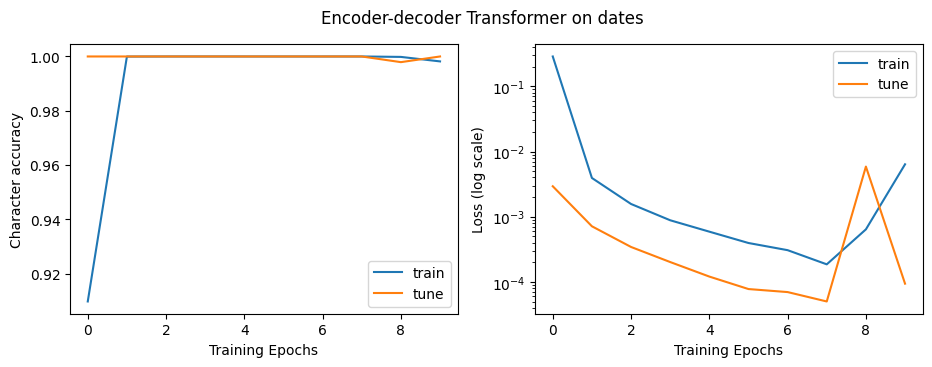

In [5]:
model.compile(loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              metrics=['accuracy'])

# Configure early stopping using the validation loss from the tune partition
stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss',
                                              patience=2,
                                              verbose=1,
                                              restore_best_weights=True)

# The history structure keeps tabs on what happened during the session
history = model.fit((source[train], decoder_input[train]), decoder_target[train],
                    batch_size=batch_size,
                    epochs=epochs,
                    verbose=2,
                    validation_data=((source[tune], decoder_input[tune]), decoder_target[tune]),
                    callbacks=[stop_early])

# Plot the accuracy and the loss by epoch for the train and tune partitions
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, metric, label in [(axes[0], 'accuracy', 'Character accuracy'), (axes[1], 'loss', 'Loss (log scale)')]:
    ax.plot(history.history[metric], label='train')
    ax.plot(history.history['val_' + metric], label='tune')
    ax.set_xlabel('Training Epochs')
    ax.set_ylabel(label)
    ax.legend()
axes[1].set_yscale('log')
plt.suptitle('Encoder-decoder Transformer on dates')
plt.show()

# Step 4 - Evaluate the model on the test set

The accuracy above is measured with teacher forcing: the decoder always sees the correct previous characters. A fairer test is to translate each test date from scratch with **greedy decoding**: start with `[start]`, predict the most likely next character, add it to the decoder input, and repeat. A translation only counts as correct if all 10 characters are right.

In [6]:
def translate(english_dates):
    """Greedy decoding for a list of English dates. Returns the predicted ISO dates as strings."""
    sources = np.array([encode_english(e) for e in english_dates])
    encoder_output, padding_mask = model.encode(sources)      # run the encoder once
    decoded = np.full((len(sources), 1), tgt_index[START])     # every translation starts with [start]
    for _ in range(date_len):                                   # an ISO date always has 10 characters
        logits, _ = model.decode(decoded, encoder_output, padding_mask)
        next_char = np.argmax(logits[:, -1, :], axis=-1)        # most likely next character
        decoded = np.concatenate([decoded, next_char[:, np.newaxis]], axis=1)
    return [''.join(tgt_vocab[i] for i in row[1:]) for row in decoded]


predictions = translate(english_test)
correct = [p == iso for p, iso in zip(predictions, iso_test)]
print('Test dates translated exactly right: {0} of {1} ({2:.1%})'.format(sum(correct), len(correct), np.mean(correct)))
print()
for i in range(10):
    print('{0:28s} -> {1}  ... {2}'.format(english_test[i], predictions[i], 'Correct!' if correct[i] else 'Incorrect'))

Test dates translated exactly right: 2000 of 2000 (100.0%)

june 5 1967                  -> 1967-06-05  ... Correct!
feb 24 2019                  -> 2019-02-24  ... Correct!
10 august 2041               -> 2041-08-10  ... Correct!
november 14 1967             -> 1967-11-14  ... Correct!
may 20 2048                  -> 2048-05-20  ... Correct!
november 14 2033             -> 2033-11-14  ... Correct!
5 march 2044                 -> 2044-03-05  ... Correct!
the 19th of december 1960    -> 1960-12-19  ... Correct!
7 december 1955              -> 1955-12-07  ... Correct!
sep 9 1959                   -> 1959-09-09  ... Correct!


# Step 5 - Testing for robustness / generalization

Now some dates we write ourselves. A few of them are things the model has never seen during training. Before running the cell, guess which ones it will get right.

In [7]:
my_dates = [
    'march 5 2021',              # a format it was trained on
    'the 1st of january 2000',
    '29 february 2024',          # a leap day
    'dec 25 1999',
    'march the 5th 2021',        # a word order it has never seen
    'july 4 2050',               # 2050 is outside 1950-2049, so it becomes [unk]
    'february 30 2021',          # not a real date
]

for english, iso in zip(my_dates, translate(my_dates)):
    words = [w if w in src_index else w + '->[unk]' for w in english.split()]
    print('{0:28s} -> {1}      (model sees: {2})'.format(english, iso, ' '.join(words)))

march 5 2021                 -> 2021-03-05      (model sees: march 5 2021)
the 1st of january 2000      -> 2000-01-01      (model sees: the 1st of january 2000)
29 february 2024             -> 2024-02-29      (model sees: 29 february 2024)
dec 25 1999                  -> 1999-12-25      (model sees: dec 25 1999)
march the 5th 2021           -> 2005-03-21      (model sees: march the 5th 2021)
july 4 2050                  -> 2043-07-04      (model sees: july 4 2050->[unk])
february 30 2021             -> 2021-02-30      (model sees: february 30 2021)


In our run, the first four dates came out right, including the leap day. The last three show the limits of what the model learned:

* **march the 5th 2021**: every word is familiar, but the model has only seen them in four fixed orders. It took the year and the day from the wrong places. It learned the patterns in its training data, not the rules of writing dates.
* **july 4 2050**: the year 2050 was never in the training data, so it became `[unk]` and the model had to guess a year.
* **february 30 2021**: the model copies the numbers it reads. Nothing in its training said which dates exist.

This is the same lesson as Step 5 of `tf.keras_rnn.ipynb`: a network does well on data like its training data, and can fail in surprising ways outside it.

# Step 6 - Look inside: cross-attention

The cross-attention weights show which English word the decoder looked at while writing each character. We plot them for the same date written in two different formats, averaged over the attention heads. Each row is an output character and each column is an input word.

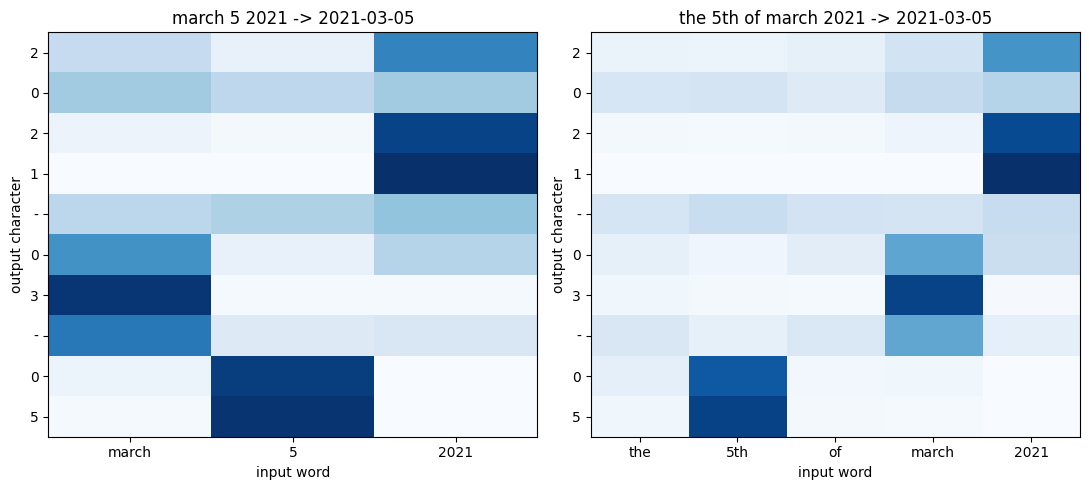

In [8]:
def plot_cross_attention(ax, english):
    """Translate one date and plot which input word each output character attended to."""
    iso = translate([english])[0]
    sources = np.array([encode_english(english)])
    encoder_output, padding_mask = model.encode(sources)
    decoded = np.array([[tgt_index[START]] + [tgt_index[c] for c in iso if c in tgt_index]])
    _, cross_scores = model.decode(decoded, encoder_output, padding_mask)    # (1, num_heads, 11, 5)
    weights = np.mean(cross_scores[0], axis=0)                               # average over the heads
    n_words = len(english.split())
    ax.imshow(weights[:len(iso), :n_words], cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set_xticks(range(n_words))
    ax.set_xticklabels(english.split())
    ax.set_yticks(range(len(iso)))
    ax.set_yticklabels(list(iso))
    ax.set_xlabel('input word')
    ax.set_ylabel('output character')
    ax.set_title('{0} -> {1}'.format(english, iso))


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_cross_attention(axes[0], 'march 5 2021')
plot_cross_attention(axes[1], 'the 5th of march 2021')
plt.tight_layout()
plt.show()

In each row, the dark cell is the input word the model mostly read while writing that character. Compare the two plots: the same output characters draw on different column positions, because the year, month and day sit in different places in the two inputs.

**Things to try**

* Set `num_layers = 2` in Step 2. Does it learn faster or better?
* Train on fewer examples (`num_examples = 2000`) and see how the test accuracy changes.
* Remove one of the four formats from `formats` in Step 1, train again, and test the missing format in Step 5. Can the model translate a format it has never seen?
* Plot the cross-attention for other dates, such as `'dec 25 1999'`.